# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

Import what you use and set the random seed. Pin those packages in `requirements.txt` and the interpreter in `.python-version`, or use `renv.lock` for R. When a result depends on the draw, record the seed in `decisions.md`. Before fitting, check each file in `data/` against the SHA-256 in `data/README.md`.


In [3]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
import hashlib


### Checksums for Files

In [4]:
EXPECTED_HASHES = {
    "yellow_tripdata_2026-01.parquet": "8b3933fe6f0d7b6d8826613c0dd724edc680ff7c49e2bd4c7635c05102728637",
    "yellow_tripdata_2026-02.parquet": "5352ca800f29c40a221ed5b0c6392c451fde7fcd236a73651bd5aea74713a26c",
    "yellow_tripdata_2026-03.parquet": "d7af794a7ac06cbbb5afb4d1df9e86d84f2e878584de708ff2ffca4bd7d234d9",
    "yellow_tripdata_2026-04.parquet": "e03b82d5722a6b21d4fbce011afd8837495202c0b5db77ff0d8d15dd80834ba8",
    "yellow_tripdata_2026-05.parquet": "9aa5a1609e2bf07d9051b7d530de05b1019e12a560ecb2c59c137c8b3a8b6750",
    "yellow_tripdata_2026-06.parquet": "f340c62a18885c56176433c9db28e97d0a8a14e6e49869276ad8afb20ebf088b",
    "yellow_tripdata_2026-07.parquet": "3260bb629c2f334055f8a566cbb02c15476b15120c45d7ad0aae46fc4bb06612",
    "yellow_tripdata_2026-08.parquet": "6683a025443afcbb28ac4f238fcbb6334767dc69fab4a16b1eb16a78dcd013cd",
}

DATA_DIR = Path("data")

def calculate_sha256(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()

print("Verifying NYC TLC dataset integrity...\n")

for filename, expected_hash in EXPECTED_HASHES.items():
    file_path = DATA_DIR / filename

    if not file_path.exists():
        raise FileNotFoundError(f"Missing dataset: {filename}")

    actual_hash = calculate_sha256(file_path)

    if actual_hash != expected_hash:
        raise ValueError(
            f"Checksum mismatch for {filename}!\n"
            f"Expected: {expected_hash}\n"
            f"Actual:   {actual_hash}"
        )

    print(f"PASS: {filename}")

print("\nAll 8 datasets verified successfully!")

Verifying NYC TLC dataset integrity...

PASS: yellow_tripdata_2026-01.parquet
PASS: yellow_tripdata_2026-02.parquet
PASS: yellow_tripdata_2026-03.parquet
PASS: yellow_tripdata_2026-04.parquet
PASS: yellow_tripdata_2026-05.parquet
PASS: yellow_tripdata_2026-06.parquet
PASS: yellow_tripdata_2026-07.parquet
PASS: yellow_tripdata_2026-08.parquet

All 8 datasets verified successfully!


## Question

![Layer diagram](fig/layers.png)

### Question and Quantity
**Question**: Can historical yellow taxi pickup patterns, including time of day, day of the week, and previous pickup activity, accurately predict the number of yellow taxi pickups in Manhattan during the next hour?

**Quantity:** hourly yellow taxi pickups in Manhattan, measured in **trips per hour**, with a **one-hour-ahead forecast window** over **January–August 2026**.

### Decision Affected by the Model

A hypothetical New York City taxi fleet manager will use the predicted hourly demand to decide how many taxis to make available in Manhattan.

If demand is expected to increase, the manager can allocate additional taxis. If demand is expected to decrease, the manager can reduce unnecessary vehicle deployment.

### Cost of Prediction Errors

There are two types of forecasting errors:

- **Underestimating demand**: Too few taxis may be available, resulting in longer passenger wait times, missed trips, and lost revenue.
- **Overestimating demand**: Too many taxis may be deployed, resulting in idle vehicles and unnecessary operating costs.

Underestimating demand is assumed to be more costly than overestimating demand.


### Decision Loss Function

To evaluate these decisions, the project will use an illustrative asymmetric cost function:

$$
L(a,y) =
c_u \max(y-ra,0)
+
\frac{c_i}{r}\max(ra-y,0)
$$

**Where:**

| Symbol | Description | Unit |
|---|---|---|
| $L(a,y)$ | Total estimated operating loss | Dollars per hour |
| $a$ | Number of taxis allocated | Taxis |
| $y$ | Actual taxi pickups during the hour | Trips per hour |
| $r$ | Average pickups served per taxi per hour | Trips per taxi-hour |
| $c_u$ | Cost of each pickup exceeding available capacity | Dollars per trip |
| $c_i$ | Cost of unused taxi capacity | Dollars per taxi-hour |

## Data

This project uses the New York City Taxi and Limousine Commission (TLC) Yellow Taxi Trip Records from January through August 2026. The dataset contains 29,703,355 individual taxi trip records across eight monthly Parquet files.


| Column                  | Description                                                                                                                                           |
| ----------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------- |
| `VendorID`              | Identifies the technology provider that supplied the taxi trip record.                                                                                |
| `tpep_pickup_datetime`  | Date and time when the taxi meter was activated at pickup.                                                                                            |
| `tpep_dropoff_datetime` | Date and time when the taxi meter was deactivated at drop-off.                                                                                        |
| `passenger_count`       | Number of passengers, as entered by the driver.                                                                                                       |
| `trip_distance`         | Total trip distance in miles, reported by the taximeter.                                                                                              |
| `RatecodeID`            | Fare rate category, such as standard fare, JFK Airport, Newark Airport, or negotiated fare.                                                           |
| `store_and_fwd_flag`    | Indicates whether the trip record was stored in the taxi's memory before being transmitted (`Y` = yes, `N` = no).                                     |
| `PULocationID`          | TLC taxi zone identifier where the passenger was picked up.                                                                                           |
| `DOLocationID`          | TLC taxi zone identifier where the passenger was dropped off.                                                                                         |
| `payment_type`          | Payment method, such as credit card, cash, dispute, or no charge.                                                                                     |
| `fare_amount`           | Metered fare based on the trip's time and distance, excluding additional charges.                                                                     |
| `extra`                 | Additional charges, such as rush-hour and overnight surcharges.                                                                                       |
| `mta_tax`               | Metropolitan Transportation Authority (MTA) tax applied to qualifying trips.                                                                          |
| `tip_amount`            | Recorded tip amount in dollars. Includes credit card tips but not cash tips.                                                                          |
| `tolls_amount`          | Total toll charges associated with the trip.                                                                                                          |
| `improvement_surcharge` | Surcharge collected to support the NYC Taxi Improvement Fund.                                                                                         |
| `total_amount`          | Total amount charged to the passenger, excluding unrecorded cash tips.                                                                                |
| `congestion_surcharge`  | New York State congestion surcharge applied to qualifying trips.                                                                                      |
| `Airport_fee`           | Additional fee for pickups at JFK or LaGuardia Airport.                                                                                               |
| `cbd_congestion_fee`    | Per-trip charge associated with the MTA Congestion Relief Zone, introduced in January 2025.                                                           |
| `request_source`        | Code describing how the trip was requested. Present in your June–August 2026 files; individual code meanings have not all been officially documented. |



Each observation represents a recorded yellow taxi trip. The relevant variables include pickup timestamps (`tpep_pickup_datetime`) and pickup location identifiers (`PULocationID`).

The data were collected through taxi technology systems and submitted to the TLC.

The records were filtered to include pickups originating in Manhattan using the TLC Taxi Zone Lookup Table. After filtering by location and date, 25,701,709 valid Manhattan pickup records remained. These were aggregated into 5,832 hourly observations covering January through August 2026.

The study period covers 243 days, corresponding to 5,832 hourly time slots before accounting for data-quality issues.

The goal is to predict the number of yellow taxi pickups in Manhattan during the next hour, measured in trips per hour.

**Data source:** [NYC TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page)

**Measurement limitations:** Recorded taxi pickups measure completed trip activity rather than all passenger requests. Unfulfilled demand is not captured. Timestamp errors, missing location identifiers, and incomplete records may also affect the observed hourly totals.

**Data availability:** The original Parquet files are stored locally in the `data/` directory rather than committed to GitHub. Instructions for downloading the files are provided in `data/README.md`.

### Data Preparation

The following steps are used to prepare the dataset:

1. Load the eight monthly Parquet files.
2. Select pickup timestamps and pickup location identifiers.
3. Filter records to Manhattan pickup zones.
4. Remove records with invalid or missing pickup information.
5. Aggregate trips into hourly pickup counts.
6. Construct a complete hourly time series.
7. Generate descriptive statistics and visualize hourly demand before fitting any models.

In [5]:
data_dir = Path("data")

files = sorted(data_dir.glob("yellow_tripdata_2026-*.parquet"))

assert len(files) == 8, f"Expected 8 files, found {len(files)}"

df = pd.concat(
    [
        pd.read_parquet(
            file,
            columns=["tpep_pickup_datetime", "PULocationID"]
        )
        for file in files
    ],
    ignore_index=True
)

print("Total records:", f"{len(df):,}")
print("Columns:", df.columns.tolist())

display(df.head())

Total records: 29,703,355
Columns: ['tpep_pickup_datetime', 'PULocationID']


,tpep_pickup_datetime,PULocationID
0,2026-01-01 00:54:04,239
1,2026-01-01 00:34:04,163
2,2026-01-01 00:57:06,43
3,2026-01-01 00:15:22,142
4,2026-01-01 00:27:13,88


This cell loads the eight monthly NYC Taxi and Limousine Commission (TLC) Yellow Taxi Trip Record Parquet files covering January through August 2026. The files are combined into one DataFrame containing the pickup timestamp (`tpep_pickup_datetime`) and pickup location identifier (`PULocationID`), which are the only fields needed to measure where and when taxi pickups occurred. Loading only these columns reduces memory use while preserving the information required for the analysis. The output confirms that 29,703,355 trip records were loaded and that the expected columns are available. At this stage, the data still include pickups from all New York City taxi zones; the next step identifies Manhattan zones and filters the records to the geographic area used in the forecasting question.

In [6]:
# Download the official taxi-zone lookup if it is not already local
lookup_path = data_dir / "taxi_zone_lookup.csv"

if not lookup_path.exists():
    lookup_url = (
        "https://d37ci6vzurychx.cloudfront.net/"
        "misc/taxi_zone_lookup.csv"
    )
    pd.read_csv(lookup_url).to_csv(lookup_path, index=False)

zones = pd.read_csv(lookup_path)

# Identify all Manhattan pickup zones
manhattan_ids = zones.loc[
    zones["Borough"] == "Manhattan",
    "LocationID"
]

# Convert timestamps and location IDs
df["tpep_pickup_datetime"] = pd.to_datetime(
    df["tpep_pickup_datetime"],
    errors="coerce"
)

df["PULocationID"] = pd.to_numeric(
    df["PULocationID"],
    errors="coerce"
)

# Retain only valid Manhattan pickups in Jan-Aug 2026
df = df.loc[
    df["PULocationID"].isin(manhattan_ids)
    & df["tpep_pickup_datetime"].ge("2026-01-01")
    & df["tpep_pickup_datetime"].lt("2026-09-01")
].copy()

# Count Manhattan pickups per hour
hourly_counts = df.groupby(
    df["tpep_pickup_datetime"].dt.floor("h")
).size()

# Construct all expected hourly time slots
all_hours = pd.date_range(
    "2026-01-01",
    "2026-08-31 23:00",
    freq="h"
)

hourly_pickups = hourly_counts.reindex(
    all_hours,
    fill_value=0
)

hourly_pickups.index.name = "hour"
hourly_pickups.name = "pickups"

print("Valid Manhattan trip records:", f"{len(df):,}")
print("Hourly observations:", f"{len(hourly_pickups):,}")
print("Zero-pickup hours:", (hourly_pickups == 0).sum())

display(hourly_pickups.head())


Valid Manhattan trip records: 25,701,709
Hourly observations: 5,832
Zero-pickup hours: 1


hour
2026-01-01 00:00:00    8053
2026-01-01 01:00:00    8588
2026-01-01 02:00:00    6387
2026-01-01 03:00:00    5166
2026-01-01 04:00:00    3184
Freq: h, Name: pickups, dtype: int64

This cell converts the raw pickup timestamps into a clean hourly demand series for Manhattan. It first loads the official TLC taxi-zone lookup table and uses the borough label to identify all Manhattan pickup locations. The pickup timestamps and location IDs are converted to consistent formats, then records with valid Manhattan pickup locations between January 1 and August 31, 2026 are retained. The filtered trips are grouped by the hour of pickup to produce the target variable: the number of yellow taxi pickups per hour. A complete hourly index is then created so that every expected time slot is represented, including hours with no recorded pickups. The output shows that 25,701,709 records remain after filtering and that the initial series contains 5,832 hourly observations. The one zero-count hour is investigated and corrected later because it corresponds to the nonexistent 2:00 AM hour created by the daylight-saving-time transition.

### Data Summary

After filtering the original 29,703,355 taxi records to include valid pickups originating in Manhattan between January and August 2026, the dataset contains 25,701,709 recorded pickups. These records were aggregated into 5,831 hourly observations.

The average number of Manhattan yellow taxi pickups was approximately 4,407 per hour, with a standard deviation of approximately 2,542 pickups. The median was 4,879.5 pickups per hour, and the maximum observed hourly count was 12,810.

The substantial variation in hourly pickup counts suggests that taxi activity changes considerably throughout the study period. These variations provide an opportunity to investigate whether historical pickup activity and calendar-based features can predict future hourly demand.

The hourly series contains one zero-count observation, which requires investigation before model training.

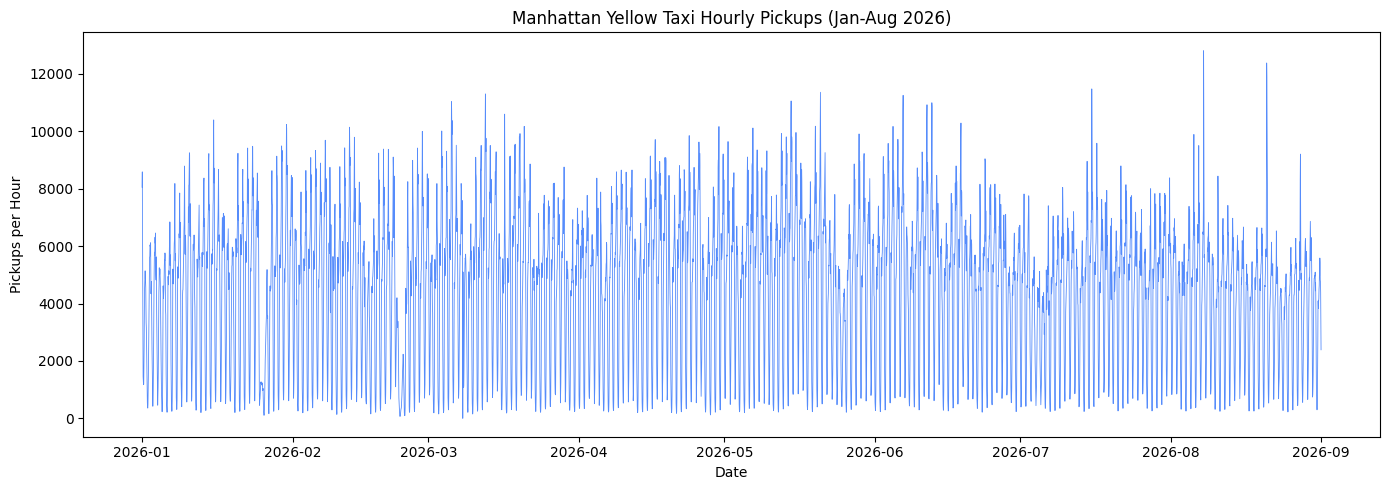

,Hourly Manhattan Pickups
count,5832.000000
mean,4407.014575
std,2541.918269
min,0.000000
25%,1941.250000
50%,4879.500000
75%,6191.000000
max,12810.000000


,count,mean,median,min,max,std
hour,,,,,,
2026-01-01,744,4275.018817,4823.5,105,10398,2601.421668
2026-02-01,672,4329.369048,4748.0,66,10144,2653.181490
2026-03-01,744,4559.055108,5032.5,0,11304,2672.818198
2026-04-01,720,4598.734722,5239.0,120,10167,2630.038714
2026-05-01,744,4754.903226,5229.0,197,11361,2670.225965
2026-06-01,720,4702.691667,5262.0,215,11255,2552.137024
2026-07-01,744,4153.822581,4651.5,237,11479,2264.034697
2026-08-01,744,3890.729839,4433.0,225,12810,2137.337803


In [7]:
Path("fig").mkdir(exist_ok=True)

# Plot raw Manhattan hourly pickup activity
plt.figure(figsize=(14, 5))

plt.plot(
    hourly_pickups.index,
    hourly_pickups.values,
    linewidth=0.6
)

plt.title("Manhattan Yellow Taxi Hourly Pickups (Jan-Aug 2026)")
plt.xlabel("Date")
plt.ylabel("Pickups per Hour")
plt.tight_layout()

plt.savefig(
    "fig/raw_hourly_pickups.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Summary statistics
summary = hourly_pickups.describe().to_frame(
    name="Hourly Manhattan Pickups"
)

display(summary)

# Additional monthly summary
monthly_summary = (
    hourly_pickups
    .resample("MS")
    .agg(["count", "mean", "median", "min", "max", "std"])
)

display(monthly_summary)


This cell performs the initial exploratory analysis before any forecasting model is fitted. The line plot shows how Manhattan yellow taxi pickups change from hour to hour across January through August 2026, making daily patterns, weekly variation, unusual observations, and broader changes over time visible. The summary table reports the number of hourly observations, average demand, standard deviation, quartiles, minimum, and maximum. The overall mean is approximately 4,407 pickups per hour, while the standard deviation of approximately 2,542 pickups shows substantial variation in demand. The median is approximately 4,880 pickups per hour, which is higher than the mean because many overnight hours have relatively low demand. The range is wide, from 0 to 12,810 pickups per hour.

The monthly summary shows that average demand increases from January through May, reaching approximately 4,755 pickups per hour in May, and then declines during July and August. August has the lowest monthly average at approximately 3,891 pickups per hour, suggesting that demand changes meaningfully over the study period. These daily and monthly patterns support using calendar variables and historical pickup counts in the forecasting model. The single zero-count observation is not genuine demand; it is the nonexistent 2:00 AM hour created by the daylight-saving-time transition and is investigated and corrected later. Overall, the exploratory analysis confirms that taxi demand varies substantially across hours and months, making a forecasting model potentially useful for taxi allocation decisions.

### Daylight Saving Time Adjustment

The study period from January 1 through August 31, 2026, covers 243 calendar days, corresponding to 5,832 expected hourly observations under the assumption of 24 hours per day.

However, daylight saving time began in New York City on March 8, 2026, when clocks advanced directly from 1:59 AM to 3:00 AM. Therefore, the local hour beginning at 2:00 AM did not occur.

The initial hourly time series included this nonexistent hour as a zero-count observation. To avoid treating an artificial zero as genuine taxi demand, the observation was removed.

After this adjustment, the dataset contains **5,831 hourly observations**, which are divided chronologically into training, validation, and testing sets.

In [8]:
# Identify hours with zero recorded Manhattan pickups
zero_hours = hourly_pickups[hourly_pickups == 0]

print("Hours with zero recorded pickups:")
display(zero_hours)

# Inspect nearby observations
for hour in zero_hours.index:
    print(f"\nObservations around {hour}:")
    display(
        hourly_pickups.loc[
            hour - pd.Timedelta(hours=3):
            hour + pd.Timedelta(hours=3)
        ]
    )


Hours with zero recorded pickups:


hour
2026-03-08 02:00:00    0
Freq: h, Name: pickups, dtype: int64


Observations around 2026-03-08 02:00:00:


hour
2026-03-07 23:00:00    7592
2026-03-08 00:00:00    7104
2026-03-08 01:00:00    6161
2026-03-08 02:00:00       0
2026-03-08 03:00:00    5100
2026-03-08 04:00:00    3267
2026-03-08 05:00:00    1473
Freq: h, Name: pickups, dtype: int64

## Split

> Hold out data the model never sees. When the decision is about a later time, hold out a later time. Record the cutoff date, or the seed and the fraction, in `decisions.md`. Do not fit, scale, or choose features on the held-out rows.

The dataset is divided chronologically into training, validation, and testing sets to evaluate the model's ability to predict future taxi demand.

- **Training set (January 1 – June 30, 2026):** Used to train the forecasting model and learn historical patterns in hourly Manhattan taxi pickups.
- **Validation set (July 1 – July 31, 2026):** Used to compare models, select hyperparameters, and assess prediction performance before final testing.
- **Testing set (August 1 – August 31, 2026):** Reserved for the final evaluation of the selected model on previously unseen observations.

A chronological split is used instead of a random split because this is a time-series forecasting problem. Randomly mixing observations from different periods could introduce information from future periods into the training process.

Any preprocessing parameters learned from the data must be fitted using training observations only. The test set will not be used for model selection or hyperparameter tuning.

The forecasting target is hourly Manhattan yellow taxi pickups, measured in trips per hour.


,Dataset,Start,End,Observations,Observations Distribution Percentage,Mean Pickups/Hour
0,Training,2026-01-01,2026-06-30 23:00:00,4343,0.744812,4539.848492
1,Validation,2026-07-01,2026-07-31 23:00:00,744,0.127594,4153.822581
2,Testing,2026-08-01,2026-08-31 23:00:00,744,0.127594,3890.729839


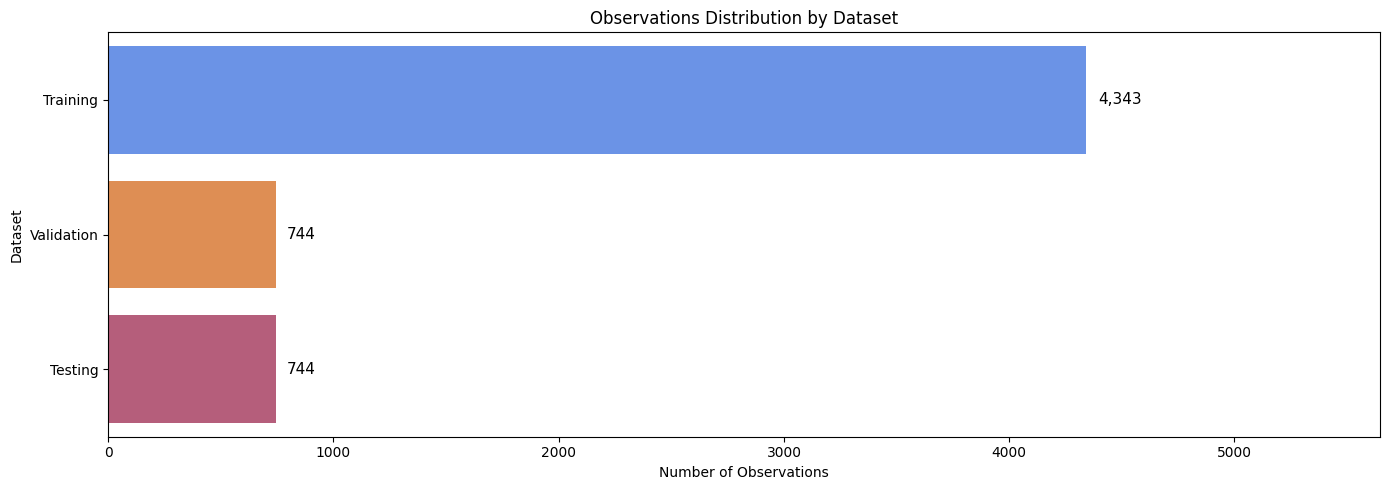

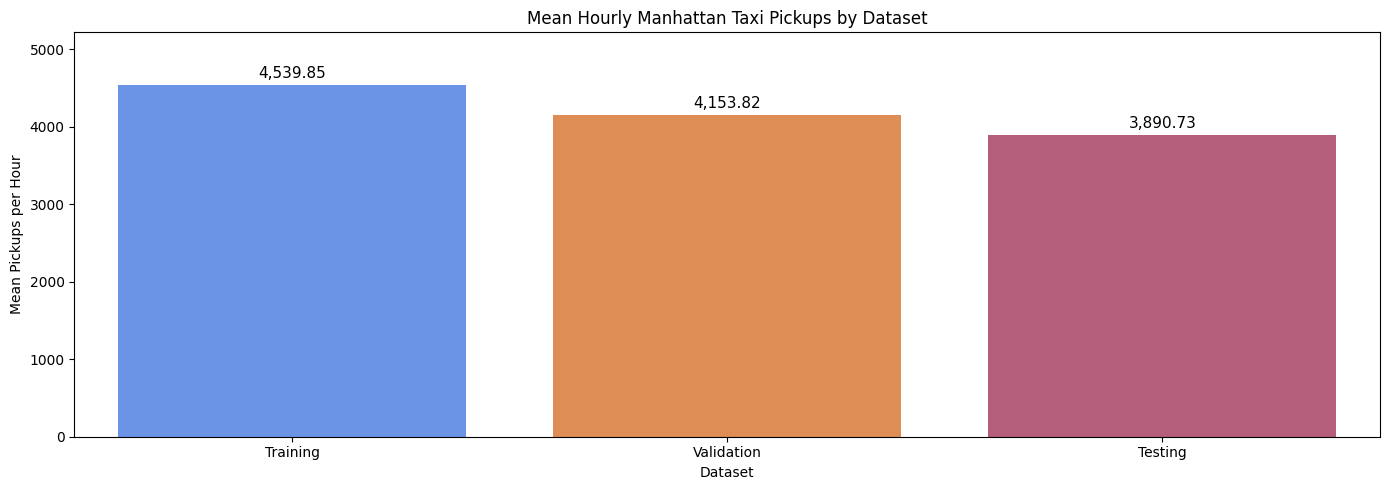

In [9]:
# Remove the nonexistent DST hour if it is still present
dst_missing_hour = pd.Timestamp("2026-03-08 02:00:00")

hourly_pickups = hourly_pickups.drop(
    dst_missing_hour,
    errors="ignore"
)

# Ensure observations are in chronological order
hourly_pickups = hourly_pickups.sort_index()

# Define chronological cutoffs
train_end = pd.Timestamp("2026-07-01")
val_end = pd.Timestamp("2026-08-01")

# Split hourly Manhattan taxi pickups
train = hourly_pickups.loc[
    hourly_pickups.index < train_end
].copy()

val = hourly_pickups.loc[
    (hourly_pickups.index >= train_end)
    & (hourly_pickups.index < val_end)
].copy()

test = hourly_pickups.loc[
    hourly_pickups.index >= val_end
].copy()

# Confirm that every observation belongs to one split
assert len(train) + len(val) + len(test) == len(hourly_pickups)

# Check that the splits do not overlap
assert train.index.max() < val.index.min()
assert val.index.max() < test.index.min()

# Show the results
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Start": [train.index.min(), val.index.min(), test.index.min()],
    "End": [train.index.max(), val.index.max(), test.index.max()],
    "Observations": [len(train), len(val), len(test)],
    "Observations Distribution Percentage": [len(train)/len(hourly_pickups), len(val)/len(hourly_pickups), len(test)/len(hourly_pickups)],
    "Mean Pickups/Hour": [
        train.mean(),
        val.mean(),
        test.mean()
    ],
})

display(split_summary)

# Observations Distribution by Dataset Plot
plt.figure(figsize=(14, 5))

ax = sns.barplot(
    data=split_summary,
    y="Dataset",
    x="Observations",
    hue="Dataset"
)

for i, row in split_summary.reset_index(drop=True).iterrows():
    count = row["Observations"]
    plt.text(
        count + 50,                     # Position after the bar
        i,                              # Bar's vertical position
        f"{count:,}",
        va="center",
        ha="left",
        fontsize=11
    )

plt.xlim(0, split_summary["Observations"].max() * 1.30)

plt.title("Observations Distribution by Dataset")
plt.xlabel("Number of Observations")
plt.ylabel("Dataset")
plt.tight_layout()

plt.show()

# Mean Pickups/Hour Plot
plt.figure(figsize=(14, 5))

ax = sns.barplot(
    data=split_summary,
    x="Dataset",
    y="Mean Pickups/Hour",
    hue="Dataset"
)

for i, row in split_summary.reset_index(drop=True).iterrows():
    count = row["Mean Pickups/Hour"]
    plt.text(
        i,                              # Horizontal position of bar
        count + 50,                     # Position above bar
        f"{count:,.2f}",
        va="bottom",
        ha="center",
        fontsize=11
    )

# Leave space above bars for labels
plt.ylim(
    0,
    split_summary["Mean Pickups/Hour"].max() * 1.15
)

plt.title("Mean Hourly Manhattan Taxi Pickups by Dataset")
plt.xlabel("Dataset")
plt.ylabel("Mean Pickups per Hour")
plt.tight_layout()

plt.show()


This cell removes the nonexistent daylight-saving-time hour, sorts the hourly observations chronologically, and divides the data into training, validation, and testing periods. The training set covers January through June and contains 4,343 observations, while July and August each contain 744 observations for validation and testing. This gives approximately 74.5% of the data to training and 12.8% to each held-out period.

The chronological split matches the way the model will be used in practice: historical data are used to forecast later demand. The validation set is used for model comparison and hyperparameter selection, while the August test set remains reserved for the final evaluation. The split checks confirm that the periods do not overlap and that every cleaned hourly observation belongs to exactly one set. The mean demand is approximately 4,540 pickups per hour in training, 4,154 in validation, and 3,891 in testing. The lower average demand in the later periods suggests some change over time, which makes the held-out August evaluation especially useful for testing whether the model generalizes beyond the training period.

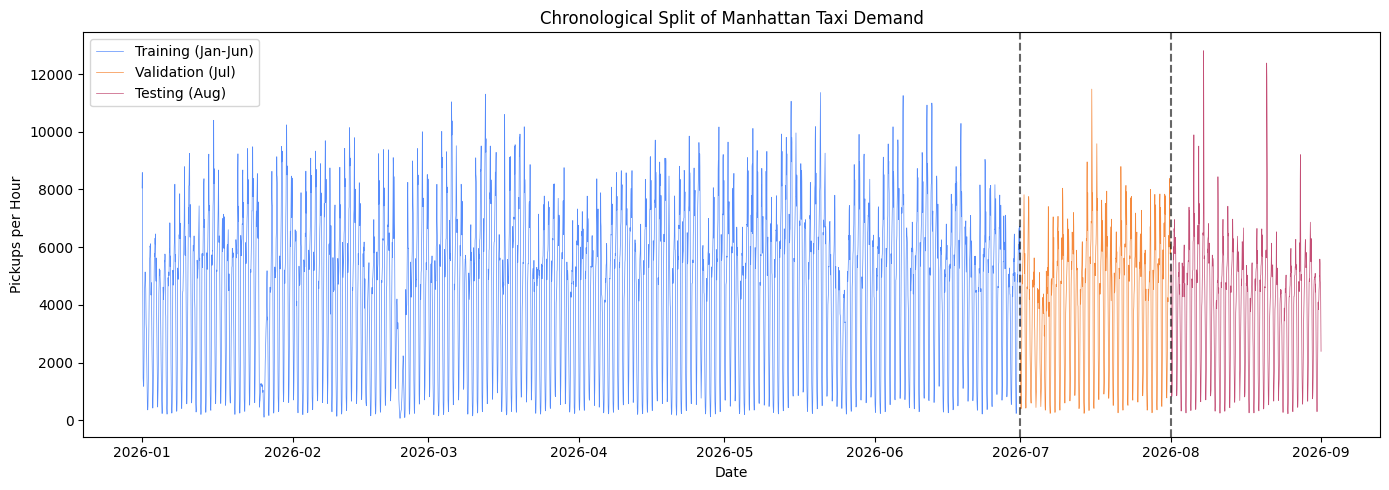

In [10]:
# Visualize the chronological data split
plt.figure(figsize=(14, 5))

plt.plot(
    train.index, train.values,
    label="Training (Jan-Jun)",
    linewidth=0.5
)

plt.plot(
    val.index, val.values,
    label="Validation (Jul)",
    linewidth=0.5
)

plt.plot(
    test.index, test.values,
    label="Testing (Aug)",
    linewidth=0.5
)

plt.axvline(
    train_end,
    color="black",
    linestyle="--",
    alpha=0.6
)

plt.axvline(
    val_end,
    color="black",
    linestyle="--",
    alpha=0.6
)


plt.title("Chronological Split of Manhattan Taxi Demand")
plt.xlabel("Date")
plt.ylabel("Pickups per Hour")
plt.legend()
plt.tight_layout()

plt.savefig(
    "fig/train_validation_test_split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


This graph shows how the hourly Manhattan taxi-demand observations are divided chronologically into training, validation, and testing periods. The training data cover January through June, the validation data cover July, and the testing data cover August. The dashed vertical lines mark the cutoff dates between these periods.

The graph confirms that the observations were separated by date rather than randomly shuffled. This is appropriate because the forecasting task uses earlier demand to predict future demand. The training period contains the largest number of observations and is used to fit the Random Forest. July is held out for comparing models and selecting hyperparameters, while August is kept completely separate for the final evaluation.

The plot also shows that average demand is somewhat lower in the later periods than in the training period. This suggests that demand changed over time and creates a realistic test of whether the model can generalize to a later month. In particular, the August test period is important because it measures performance on data the model never saw during training or model selection.


## Baseline

A seasonal naive forecasting model is used as the baseline for predicting hourly yellow taxi pickups in Manhattan. The baseline predicts that demand for a given hour will equal the number of pickups recorded during the same hour one week earlier.

The baseline prediction is defined as:

$$
\hat{y}_t = y_{t-168}
$$

where:

- $\hat{y}_t$ is the predicted number of pickups for hour $t$.
- $y_{t-168}$ is the observed pickup count at the corresponding hour seven days earlier.
- $168$ represents the number of hours in seven days.

This baseline is appropriate because taxi demand may follow recurring weekly patterns influenced by commuting schedules, weekdays, and weekends.

The baseline is evaluated on the July 2026 validation set and August 2026 test set using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). Both metrics are measured in pickups per hour.

The baseline uses only previously observed pickup counts to generate forecasts. It serves as a benchmark for determining whether the machine learning model improves prediction performance.


In [11]:
# Predict each hour using the same local hour
# seven calendar days earlier.
previous_week = hourly_pickups.index - pd.Timedelta(days=7)

baseline_predictions = pd.Series(
    hourly_pickups.reindex(previous_week).to_numpy(),
    index=hourly_pickups.index,
    name="baseline_prediction"
)

# Split the predictions into validation and test periods
baseline_val = baseline_predictions.reindex(val.index)
baseline_test = baseline_predictions.reindex(test.index)

# Ensure all held-out predictions are available
assert baseline_val.notna().all(), "Missing validation predictions"
assert baseline_test.notna().all(), "Missing test predictions"

print("Baseline predictions created successfully.")

# Display sample predictions
baseline_examples = pd.DataFrame({
    "Actual Pickups": val,
    "Predicted Pickups": baseline_val,
    "Residual": val - baseline_val
})

display(baseline_examples.head(10))


Baseline predictions created successfully.


,Actual Pickups,Predicted Pickups,Residual
hour,,,
2026-07-01 00:00:00,2268,2030.0,238.0
2026-07-01 01:00:00,1153,956.0,197.0
2026-07-01 02:00:00,629,563.0,66.0
2026-07-01 03:00:00,396,370.0,26.0
2026-07-01 04:00:00,472,378.0,94.0
2026-07-01 05:00:00,878,692.0,186.0
2026-07-01 06:00:00,1807,1854.0,-47.0
2026-07-01 07:00:00,3089,3695.0,-606.0
2026-07-01 08:00:00,4908,5575.0,-667.0


This cell creates the seasonal-naive baseline forecast. For each hour, the predicted demand is the number of pickups observed during the same hour exactly seven days earlier, or 168 hours earlier. This provides a simple benchmark that captures recurring weekly patterns without fitting a complex machine-learning model.

The baseline predictions are created for the full hourly series and then separated into the July validation period and the August test period. The checks confirm that every held-out hour has a corresponding prediction from the previous week. The sample output shows that the baseline can follow broad weekly demand patterns, but it may miss changes from one week to the next, such as shifts in weather, events, seasonal demand, or overall activity. The Random Forest model will be evaluated against this baseline to determine whether additional calendar and lag features provide meaningful improvement.

In [12]:
def evaluate_forecast(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    return {
        "MAE (pickups/hour)": mae,
        "RMSE (pickups/hour)": rmse
    }

# Evaluate on July validation data
val_metrics = evaluate_forecast(val, baseline_val)

# Evaluate on August test data
test_metrics = evaluate_forecast(test, baseline_test)

baseline_results = pd.DataFrame(
    [val_metrics, test_metrics],
    index=["Validation (July)", "Test (August)"]
)

print("Seasonal Naive Baseline Performance:")
display(baseline_results.round(2))


Seasonal Naive Baseline Performance:


,MAE (pickups/hour),RMSE (pickups/hour)
Validation (July),658.70,985.45
Test (August),445.35,860.41


This cell evaluates the seasonal-naive baseline using two out-of-sample forecasting metrics: Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). Both metrics are reported in pickups per hour, so they directly describe the forecasting error in the units of the target variable.

On the July validation set, the baseline has an MAE of approximately 659 pickups per hour. This means that, on average, the baseline forecast differs from the actual hourly demand by about 659 pickups. Relative to July's average demand of approximately 4,154 pickups per hour, this is an error of about 15.9% of a typical hour. The July RMSE is approximately 985 pickups per hour, meaning that larger errors increase the overall score and that some hourly forecasts are substantially worse than the average absolute error.

On the August test set, the baseline has an MAE of approximately 445 pickups per hour, or about 11.4% of August's average demand of approximately 3,891 pickups per hour. Its RMSE is approximately 860 pickups per hour, which is about 22.1% of average August demand. The RMSE is higher than the MAE in both periods because RMSE gives extra weight to unusually large errors. This suggests that the baseline usually follows the weekly pattern reasonably well but can miss specific high- or low-demand hours. These results establish the benchmark that the Random Forest must outperform on data it did not use for training.

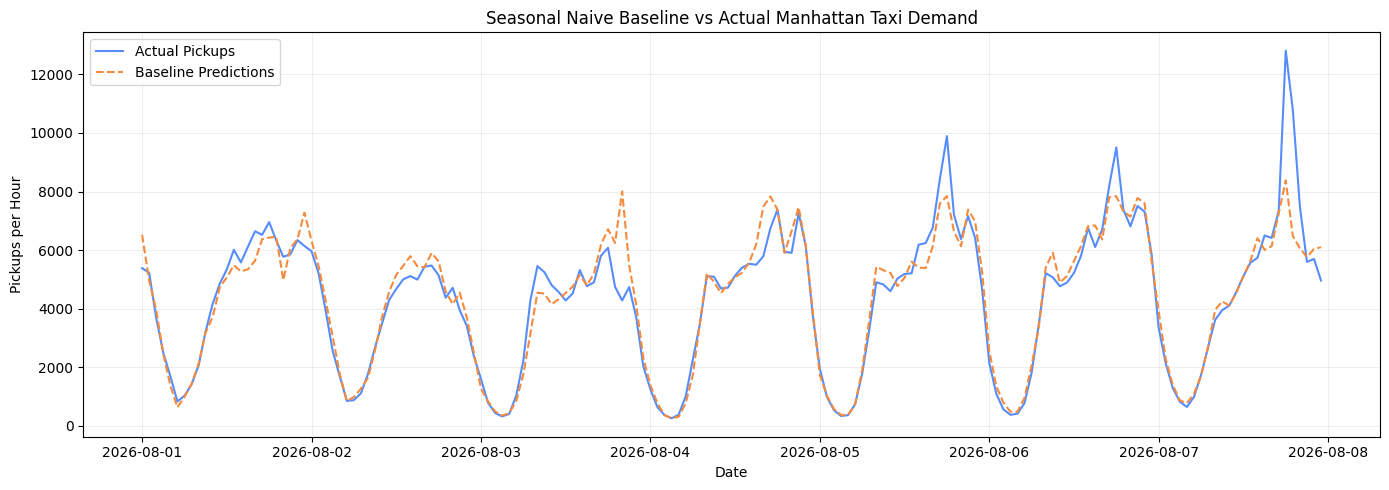

In [13]:
# Select the first week of August
plot_start = "2026-08-01"
plot_end = "2026-08-07 23:00"

actual_week = test.loc[plot_start:plot_end]
predicted_week = baseline_test.loc[plot_start:plot_end]

plt.figure(figsize=(14, 5))

plt.plot(
    actual_week.index,
    actual_week.values,
    label="Actual Pickups",
    linewidth=1.5
)

plt.plot(
    predicted_week.index,
    predicted_week.values,
    label="Baseline Predictions",
    linestyle="--",
    linewidth=1.5
)

plt.title("Seasonal Naive Baseline vs Actual Manhattan Taxi Demand")
plt.xlabel("Date")
plt.ylabel("Pickups per Hour")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "fig/baseline_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


This plot compares the seasonal-naive forecast with the actual Manhattan pickup counts during the first week of August 2026. The baseline generally follows the repeated daily shape of taxi demand: pickups fall during overnight hours, rise during the morning and daytime, and fall again late at night. This close alignment shows that the previous week's same-hour demand captures important weekly and intraday structure.

However, the forecast does not always capture sudden changes in demand. For example, the actual series contains several sharp peaks that are higher than the baseline prediction, including a large spike near August 8. The baseline also occasionally overpredicts demand when the current week is lower than the previous week. These differences illustrate the main limitation of a seasonal-naive forecast: it repeats the previous week's pattern but cannot respond to new events or short-term changes. The plot therefore provides visual evidence for using the seasonal-naive method as a reasonable benchmark while testing whether the Random Forest can reduce these remaining errors.


## Model

### Random Forest Regression

A Random Forest Regressor is used to predict the number of yellow taxi pickups in Manhattan during the next hour. Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees to model nonlinear relationships between input features and the target variable.

The model uses calendar-based and historical pickup features:

- Hour of day
- Day of week
- Month
- Weekend indicator
- Number of pickups one hour earlier
- Number of pickups 24 hours earlier
- Number of pickups during the same hour seven days earlier

The prediction from a Random Forest with \(B\) decision trees is:

$$
\hat{y}_t = \frac{1}{B}\sum_{b=1}^{B} f_b(X_t)
$$
where:

- $\hat{y}_t$ is the predicted number of Manhattan taxi pickups for hour $t$.
- $B$ is the number of decision trees.
- $f_b$ is the prediction made by the $b$-th decision tree.
- $X_t$ represents the calendar and historical pickup features available before the forecast hour.



Each decision tree recursively partitions the feature space to reduce squared prediction error. The Random Forest averages the predictions of multiple trees to produce a more stable forecast.

### Model Assumptions

The model assumes that historical hourly pickup patterns provide useful information about future taxi activity. It also assumes that the relationships between calendar features, previous pickup counts, and future demand remain sufficiently stable across the training, validation, and testing periods.

The least reliable assumption is that historical patterns remain stable during unusual events, holidays, extreme weather, or unexpected changes in transportation demand.

### Training and Evaluation

The model is trained using observations from January through June 2026. July 2026 is used for hyperparameter selection, while August 2026 is reserved for the final evaluation.

Predictions are evaluated using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE), measured in pickups per hour.

Model performance is compared against the seasonal naive baseline using the same validation and testing periods.

The forecasting experiment assumes that actual pickup totals from previous hours are available when making each new one-hour-ahead prediction.


### Random Forest Feature Engineering

In [14]:
# Prepare hourly demand data
demand = hourly_pickups.sort_index().copy()

# Create a dataframe containing the target
model_data = pd.DataFrame({
    "pickups": demand
})

# Calendar features
model_data["hour"] = model_data.index.hour
model_data["day_of_week"] = model_data.index.dayofweek
model_data["month"] = model_data.index.month

model_data["is_weekend"] = (
    model_data["day_of_week"] >= 5
).astype(int)

# Historical pickup features
# Reindex by timestamp rather than row position.
# This handles the removed daylight saving time hour.
for lag in [1, 24, 168]:
    previous_times = (
        model_data.index - pd.Timedelta(hours=lag)
    )

    model_data[f"lag_{lag}"] = demand.reindex(
        previous_times
    ).to_numpy()

# Define the target and features
target_col = "pickups"

feature_cols = [
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1",
    "lag_24",
    "lag_168"
]

# Remove rows missing required historical features
model_data = model_data.dropna(
    subset=feature_cols + [target_col]
)

# Split the model dataframe chronologically
train_model = model_data.loc[
    model_data.index < "2026-07-01"
].copy()

val_model = model_data.loc[
    (model_data.index >= "2026-07-01")
    & (model_data.index < "2026-08-01")
].copy()

test_model = model_data.loc[
    (model_data.index >= "2026-08-01")
    & (model_data.index < "2026-09-01")
].copy()

# Separate features and targets
X_train = train_model[feature_cols]
y_train = train_model[target_col]

X_val = val_model[feature_cols]
y_val = val_model[target_col]

X_test = test_model[feature_cols]
y_test = test_model[target_col]

# Ensure July and August are fully represented
assert X_val.index.equals(val.index)
assert X_test.index.equals(test.index)

print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Testing observations:", len(X_test))

print("\nFeatures used:")
print(feature_cols)

display(X_train.head())


Training observations: 4172
Validation observations: 744
Testing observations: 744

Features used:
['hour', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_24', 'lag_168']


,hour,day_of_week,month,is_weekend,lag_1,lag_24,lag_168
hour,,,,,,,
2026-01-08 00:00:00,0,3,1,0,2712.0,1132.0,8053.0
2026-01-08 01:00:00,1,3,1,0,1491.0,584.0,8588.0
2026-01-08 02:00:00,2,3,1,0,727.0,373.0,6387.0
2026-01-08 03:00:00,3,3,1,0,464.0,246.0,5166.0
2026-01-08 04:00:00,4,3,1,0,309.0,286.0,3184.0


This cell prepares the features used by the Random Forest model. Calendar variables represent the hour of day, day of the week, month, and whether the observation falls on a weekend. These variables allow the model to learn recurring daily, weekly, and monthly demand patterns.

The three lag features represent previously observed pickup activity. `lag_1` is the number of pickups during the previous hour, `lag_24` is the number of pickups during the same hour one day earlier, and `lag_168` is the number of pickups during the same hour seven days earlier. These features were selected to capture short-term momentum, daily seasonality, and weekly seasonality. The lag values are matched by timestamp rather than row position so that the removed daylight-saving-time hour does not shift the historical relationships.

Rows without a complete history are removed because the model cannot calculate all three lag features for the earliest observations. The resulting model data contain 4,172 training observations and 744 observations in each held-out period. The validation and test index checks confirm that all July and August hours are represented and that the features are constructed without using the actual demand from the forecast hour.

### Train and Select Random Forest Model

In [15]:
# Candidate Random Forest configurations
model_configs = [
    {
        "n_estimators": 100,
        "max_depth": 10,
        "min_samples_leaf": 5
    },
    {
        "n_estimators": 200,
        "max_depth": 15,
        "min_samples_leaf": 3
    },
    {
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 5
    }
]

models = []
validation_results = []

for config in model_configs:

    rf = RandomForestRegressor(
        **config,
        random_state=42,
        n_jobs=-1
    )

    # Train using January-June only
    rf.fit(X_train, y_train)

    # Evaluate using July
    predictions = rf.predict(X_val)

    metrics = evaluate_forecast(
        y_val,
        predictions
    )

    models.append(rf)

    validation_results.append({
        **config,
        **metrics
    })

# Display validation comparison
rf_validation_results = pd.DataFrame(
    validation_results
)

display(
    rf_validation_results.sort_values(
        "MAE (pickups/hour)"
    ).round(2)
)

# Select model with lowest July MAE
best_index = rf_validation_results[
    "MAE (pickups/hour)"
].idxmin()

best_model = models[best_index]

best_config = model_configs[best_index]

print("Selected Random Forest settings:")
print(best_config)

print("\nBest July validation MAE:")
print(
    round(
        rf_validation_results.loc[
            best_index,
            "MAE (pickups/hour)"
        ],
        2
    )
)


,n_estimators,max_depth,min_samples_leaf,MAE (pickups/hour),RMSE (pickups/hour)
1,200,15.0,3,325.79,490.71
2,200,NaN,5,332.42,499.67
0,100,10.0,5,336.43,503.49


Selected Random Forest settings:
{'n_estimators': 200, 'max_depth': 15, 'min_samples_leaf': 3}

Best July validation MAE:
325.79


This cell trains and compares three Random Forest configurations. Each candidate is fit using only the January–June training observations, while the July validation observations are used to compare performance. The candidate settings vary the number of trees, maximum tree depth, and minimum number of observations required in a leaf. These settings control the complexity of the forest and help evaluate whether a more flexible model improves forecasting accuracy.

The candidates are compared using MAE and RMSE in pickups per hour. The configuration with 200 trees, a maximum depth of 15, and a minimum leaf size of 3 performs best on the July validation set, with an MAE of approximately 325.79 pickups per hour and an RMSE of approximately 490.71 pickups per hour. This configuration is selected because it has the lowest validation MAE. The August test period is not used for this selection, so it remains an independent held-out evaluation of the chosen model.

### Random Forest Evaluation

In [16]:
rf_val_pred = pd.Series(
    best_model.predict(X_val),
    index=X_val.index,
    name="Random Forest"
)

# Predict August test demand
rf_test_pred = pd.Series(
    best_model.predict(X_test),
    index=X_test.index,
    name="Random Forest"
)

# Evaluate both periods
rf_val_metrics = evaluate_forecast(
    y_val, rf_val_pred
)

rf_test_metrics = evaluate_forecast(
    y_test, rf_test_pred
)

rf_results = pd.DataFrame(
    [rf_val_metrics, rf_test_metrics],
    index=["Validation (July)", "Test (August)"]
)

print("Random Forest Performance:")
display(rf_results.round(2))

# Preview actual vs predicted demand
rf_examples = pd.DataFrame({
    "Actual Pickups": y_test,
    "Random Forest Prediction": rf_test_pred,
    "Residual": y_test - rf_test_pred
})

display(rf_examples.head(10))


Random Forest Performance:


,MAE (pickups/hour),RMSE (pickups/hour)
Validation (July),325.79,490.71
Test (August),283.88,509.20


,Actual Pickups,Random Forest Prediction,Residual
hour,,,
2026-08-01 00:00:00,5383,5493.091006,-110.091006
2026-08-01 01:00:00,5225,4157.972285,1067.027715
2026-08-01 02:00:00,3674,3744.620008,-70.620008
2026-08-01 03:00:00,2494,2360.376797,133.623203
2026-08-01 04:00:00,1696,1367.182507,328.817493
2026-08-01 05:00:00,829,770.213232,58.786768
2026-08-01 06:00:00,1023,1082.314113,-59.314113
2026-08-01 07:00:00,1405,1595.936249,-190.936249
2026-08-01 08:00:00,2053,2280.304158,-227.304158


This cell evaluates the selected Random Forest on both the July validation period and the untouched August test period. The model achieves a July MAE of approximately 325.79 pickups per hour and an RMSE of approximately 490.71 pickups per hour. On the August test set, the MAE decreases to approximately 283.88 pickups per hour, while the RMSE is approximately 509.20 pickups per hour.

The lower August MAE means that the model's typical absolute error is smaller during the test month. However, the slightly higher August RMSE indicates that a few larger errors remain and are being emphasized by the squared-error metric. This difference is important because a model can be accurate for most hours while still missing unusual demand spikes. The example table compares actual pickups, predictions, and residuals, where a positive residual means the model underestimated demand and a negative residual means it overestimated demand. These residuals are later used to compare the Random Forest with the seasonal-naive baseline and to calibrate the taxi-allocation decision rule.

### Baseline vs Random Forest

In [17]:
comparison = pd.DataFrame({
    "Dataset": [
        "July Validation",
        "July Validation",
        "August Test",
        "August Test"
    ],
    "Model": [
        "Seasonal Naive",
        "Random Forest",
        "Seasonal Naive",
        "Random Forest"
    ],
    "MAE (pickups/hour)": [
        val_metrics["MAE (pickups/hour)"],
        rf_val_metrics["MAE (pickups/hour)"],
        test_metrics["MAE (pickups/hour)"],
        rf_test_metrics["MAE (pickups/hour)"]
    ],
    "RMSE (pickups/hour)": [
        val_metrics["RMSE (pickups/hour)"],
        rf_val_metrics["RMSE (pickups/hour)"],
        test_metrics["RMSE (pickups/hour)"],
        rf_test_metrics["RMSE (pickups/hour)"]
    ]
})

display(comparison.round(2))

# Calculate improvement over baseline
july_improvement = (
    1 -
    rf_val_metrics["MAE (pickups/hour)"] /
    val_metrics["MAE (pickups/hour)"]
) * 100

august_improvement = (
    1 -
    rf_test_metrics["MAE (pickups/hour)"] /
    test_metrics["MAE (pickups/hour)"]
) * 100

print(
    f"July MAE improvement: "
    f"{july_improvement:.2f}%"
)

print(
    f"August MAE improvement: "
    f"{august_improvement:.2f}%"
)


,Dataset,Model,MAE (pickups/hour),RMSE (pickups/hour)
0,July Validation,Seasonal Naive,658.70,985.45
1,July Validation,Random Forest,325.79,490.71
2,August Test,Seasonal Naive,445.35,860.41
3,August Test,Random Forest,283.88,509.20


July MAE improvement: 50.54%
August MAE improvement: 36.26%


This cell compares the seasonal-naive baseline with the selected Random Forest using the same validation and test periods. On the July validation set, the Random Forest reduces MAE from approximately 658.70 to 325.79 pickups per hour, an improvement of about 50.54%. On the August test set, the Random Forest reduces MAE from approximately 445.35 to 283.88 pickups per hour, an improvement of about 36.26%.

The Random Forest also lowers RMSE from 985.45 to 490.71 pickups per hour in July and from 860.41 to 509.20 pickups per hour in August. This indicates that the Random Forest improves both the typical absolute error and the effect of larger errors relative to the baseline. The improvement is smaller in August than in July, which may reflect changes in demand patterns across months, but the model still performs better on the untouched test set. These results show where the more complex model wins: it uses recent pickup activity and calendar features to capture changes that the previous-week baseline cannot. The baseline remains useful as a transparent benchmark, but the Random Forest provides more accurate forecasts for this dataset.

### Random Forest Prediction Plot

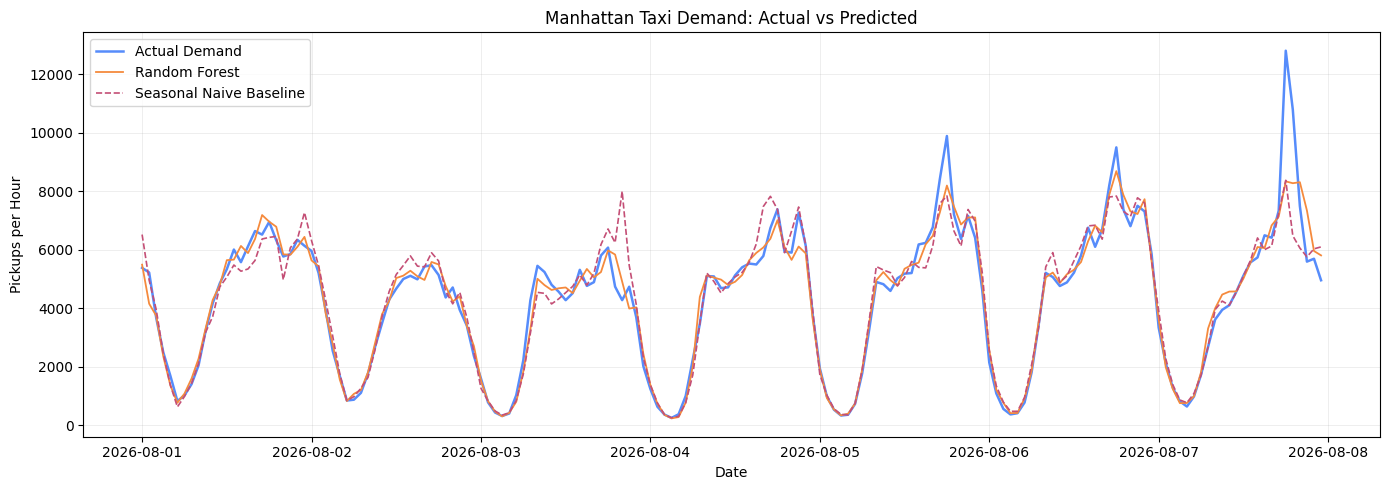

In [18]:
plot_start = "2026-08-01"
plot_end = "2026-08-07 23:00"

actual_week = y_test.loc[plot_start:plot_end]
rf_week = rf_test_pred.loc[plot_start:plot_end]
baseline_week = baseline_test.loc[plot_start:plot_end]

plt.figure(figsize=(14, 5))

plt.plot(
    actual_week.index,
    actual_week,
    label="Actual Demand",
    linewidth=1.8
)

plt.plot(
    rf_week.index,
    rf_week,
    label="Random Forest",
    linewidth=1.3
)

plt.plot(
    baseline_week.index,
    baseline_week,
    label="Seasonal Naive Baseline",
    linestyle="--",
    linewidth=1.2
)

plt.title(
    "Manhattan Taxi Demand: Actual vs Predicted"
)

plt.xlabel("Date")
plt.ylabel("Pickups per Hour")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

Path("fig").mkdir(exist_ok=True)

plt.savefig(
    "fig/random_forest_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


This plot compares actual Manhattan taxi demand with predictions from the Random Forest and the seasonal-naive baseline during the first week of August 2026. Both models capture the strong daily cycle: demand falls overnight, rises during the day, and falls again late at night. The Random Forest generally follows the actual series more closely than the seasonal-naive baseline, especially when the current week's demand differs from the corresponding hour in the previous week.

The plot also shows that both models can smooth or underestimate sharp demand spikes. For example, the largest actual peaks are higher than the predictions, indicating that unusual surges are difficult to anticipate using only the available calendar and lag features. The Random Forest usually reduces the size of these deviations relative to the baseline, but it does not eliminate them. This visual result agrees with the numerical comparison: the Random Forest has lower MAE and RMSE than the seasonal-naive model, while the remaining gaps show why residual and decision-loss analysis are still necessary.

## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.


## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.


## Decision

### Taxi Allocation and Operating Loss

The forecasting models are evaluated based on their ability to support hourly taxi allocation decisions in Manhattan.

A hypothetical fleet manager uses predicted hourly demand to determine how many taxis should be available. The decision accounts for the costs of insufficient taxi capacity and unnecessary idle capacity.

The project uses the following illustrative assumptions:

| Parameter | Value | Description |
|:---:|:---:|---|
| $r$ | 2 | Pickups served per taxi per hour |
| $c_u$ | \$15 | Cost per pickup exceeding available capacity |
| $c_i$ | \$8 | Cost per taxi-hour of unused capacity |


These values are hypothetical and are used to compare the forecasting models rather than estimate actual NYC taxi fleet expenses.

The operating loss is defined as:

$$
L(a,y)=c_u\max(y-ra,0)+\frac{c_i}{r}\max(ra-y,0)
$$

where:

- $a$ is the number of taxis allocated.
- $y$ is actual hourly pickup demand.
- $r$ is the number of pickups served per taxi per hour.
- $c_u$ is the cost of insufficient capacity per pickup.
- $c_i$ is the cost of unused capacity per taxi-hour.

### Allocation Decision Rule

Because underestimating demand is assumed to be more expensive than overestimating demand, the allocation rule includes a safety adjustment.

The adjustment is estimated from July validation residuals using the asymmetric loss ratio:

$$
q=\frac{c_u}{c_u+c_i/r}
$$

The adjusted allocation is:

$$
a_t=\max\left(0,\left\lceil
\frac{\max(0,\hat{y}_t+s)}{r}
\right\rceil\right)
$$

where:

- $\hat{y}_t$ is predicted hourly demand.
- $s$ is a model-specific residual quantile estimated using July validation data.
- $r$ is the number of pickups each taxi can serve per hour.
- $a_t$ is the resulting whole-number taxi allocation.

### Held-Out Decision Evaluation

The Seasonal Naive Baseline and Random Forest are evaluated using the same operating-cost assumptions.

July validation data are used to estimate each model's safety adjustment. August test observations are then used to calculate the final held-out decision loss.

Results are reported as estimated dollars per hour. Lower decision loss indicates a more cost-effective allocation under the assumed operating-cost model.


### Decision Loss: Operating Cost Assumptions

In [53]:
# Illustrative operating cost assumptions
r = 2.0        # Pickups per taxi per hour
c_u = 15.0     # Dollars per unmet pickup
c_i = 8.0      # Dollars per idle taxi-hour

# Asymmetric loss quantile
target_quantile = c_u / (c_u + c_i / r)

print(f"Decision quantile: {target_quantile:.4f}")


# Convert predicted demand into allocated taxis
def allocate_taxis(predictions, adjustment=0):
    adjusted = np.maximum(
        0,
        np.asarray(predictions, dtype=float) + adjustment
    )

    return np.ceil(adjusted / r).astype(int)


# Calculate operating loss for actual demand
def decision_loss(actual, allocated):
    actual = np.asarray(actual, dtype=float)
    allocated = np.asarray(allocated, dtype=float)

    capacity = allocated * r

    unmet_demand = np.maximum(actual - capacity, 0)
    excess_capacity = np.maximum(capacity - actual, 0)

    loss = (
        c_u * unmet_demand
        + (c_i / r) * excess_capacity
    )

    return loss


# Estimate a safety adjustment using July errors
def calibrate_adjustment(actual, predictions):
    residuals = (
        np.asarray(actual, dtype=float)
        - np.asarray(predictions, dtype=float)
    )

    return float(
        np.quantile(
            residuals,
            target_quantile,
            method="higher"
        )
    )


# Calibrate the models using July only
baseline_adjustment = calibrate_adjustment(
    val, baseline_val
)

rf_adjustment = calibrate_adjustment(
    y_val, rf_val_pred
)

print(
    f"Baseline adjustment: {baseline_adjustment:.2f} pickups"
)

print(
    f"Random Forest adjustment: {rf_adjustment:.2f} pickups"
)


Decision quantile: 0.7895
Baseline adjustment: 540.00 pickups
Random Forest adjustment: 231.17 pickups


This cell defines the illustrative operating-cost assumptions and converts demand forecasts into taxi-allocation decisions. Each taxi is assumed to serve two pickups per hour, an unmet pickup costs \\$15, and unused capacity costs \\$8 per taxi-hour. Because the shortage cost is higher than the idle-capacity cost, underestimating demand is treated as more serious than overestimating demand.

The resulting decision quantile is approximately 0.7895. The model-specific safety adjustment is estimated from July validation residuals, so the adjustment is calibrated only on data available before the August test period. The seasonal-naive forecast receives an adjustment of 540 pickups, while the Random Forest receives a smaller adjustment of approximately 231 pickups because its validation residuals are generally smaller. The allocation function adds the adjustment to the predicted demand, converts pickups into taxis using the assumed service rate, and rounds up to a whole number of taxis. This creates an explicit link between the forecast and the operational decision.

### Held-Out Decision Loss Evaluation

In [20]:
# Calculate July taxi allocations
baseline_val_taxis = allocate_taxis(
    baseline_val,
    baseline_adjustment
)

rf_val_taxis = allocate_taxis(
    rf_val_pred,
    rf_adjustment
)

# Calculate August taxi allocations
baseline_test_taxis = allocate_taxis(
    baseline_test,
    baseline_adjustment
)

rf_test_taxis = allocate_taxis(
    rf_test_pred,
    rf_adjustment
)

# Calculate operating losses
baseline_val_loss = decision_loss(
    val, baseline_val_taxis
)

rf_val_loss = decision_loss(
    y_val, rf_val_taxis
)

baseline_test_loss = decision_loss(
    test, baseline_test_taxis
)

rf_test_loss = decision_loss(
    y_test, rf_test_taxis
)

# Summary comparison
decision_results = pd.DataFrame({
    "Dataset": [
        "July Validation",
        "July Validation",
        "August Test",
        "August Test"
    ],
    "Model": [
        "Seasonal Naive",
        "Random Forest",
        "Seasonal Naive",
        "Random Forest"
    ],
    "Mean Loss ($/hour)": [
        np.mean(baseline_val_loss),
        np.mean(rf_val_loss),
        np.mean(baseline_test_loss),
        np.mean(rf_test_loss)
    ],
    "Total Loss ($)": [
        np.sum(baseline_val_loss),
        np.sum(rf_val_loss),
        np.sum(baseline_test_loss),
        np.sum(rf_test_loss)
    ]
})

print("Taxi Allocation Decision-Loss Comparison:")
display(decision_results.round(2))

# Calculate August cost reduction
baseline_cost = np.mean(baseline_test_loss)
rf_cost = np.mean(rf_test_loss)

cost_improvement = (
    (baseline_cost - rf_cost) / baseline_cost
) * 100

print(
    f"August baseline cost: ${baseline_cost:,.2f}/hour"
)

print(
    f"August Random Forest cost: ${rf_cost:,.2f}/hour"
)

print(
    f"August decision-cost reduction: {cost_improvement:.2f}%"
)


Taxi Allocation Decision-Loss Comparison:


,Dataset,Model,Mean Loss ($/hour),Total Loss ($)
0,July Validation,Seasonal Naive,5061.60,3765833.0
1,July Validation,Random Forest,2525.00,1878602.0
2,August Test,Seasonal Naive,3897.28,2899574.0
3,August Test,Random Forest,2382.85,1772839.0


August baseline cost: $3,897.28/hour
August Random Forest cost: $2,382.85/hour
August decision-cost reduction: 38.86%


This cell applies the calibrated allocation rules and evaluates the resulting decisions using the asymmetric operating-loss function. On the August held-out test set, the seasonal-naive strategy has an average estimated loss of approximately \\$3,897.28 per hour, while the Random Forest strategy has an average estimated loss of approximately \\$2,382.85 per hour. This corresponds to an estimated decision-loss reduction of 38.86% when using the Random Forest.

The same pattern appears in July validation, where average loss decreases from approximately \\$5,061.60 per hour for the seasonal-naive strategy to approximately \\$2,525.00 per hour for the Random Forest. The August results are the more important evidence because August was not used to select the model or calibrate its final test performance. These values are illustrative rather than estimates of actual NYC fleet costs, but they show how improved forecasts can translate into fewer costly shortages and less unnecessary taxi capacity under the stated assumptions.

### Decision Loss Comparison Plot

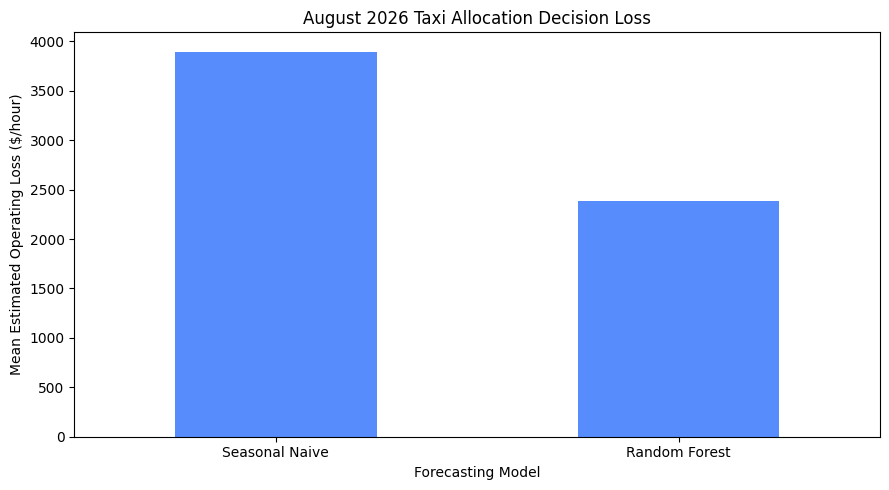

In [21]:
august_costs = pd.Series({
    "Seasonal Naive": np.mean(baseline_test_loss),
    "Random Forest": np.mean(rf_test_loss)
})

plt.figure(figsize=(9, 5))

august_costs.plot(kind="bar")

plt.title("August 2026 Taxi Allocation Decision Loss")
plt.ylabel("Mean Estimated Operating Loss ($/hour)")
plt.xlabel("Forecasting Model")
plt.xticks(rotation=0)
plt.tight_layout()

Path("fig").mkdir(exist_ok=True)

plt.savefig(
    "fig/decision_loss_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


This bar chart summarizes the August held-out decision-loss comparison in the units that matter for the fleet-allocation decision. The Random Forest bar is lower than the seasonal-naive bar, showing an average estimated operating loss of approximately \\$2,383 per hour compared with approximately \\$3,897 per hour for the baseline. The visual difference represents an estimated reduction of about \\$1,514 per hour, or 38.86%, under the illustrative cost assumptions.

The plot is not a direct estimate of actual business profit or savings. It is a model-based comparison using assumed shortage and idle-capacity costs, with the safety adjustments calibrated from July and evaluated on August. Its purpose is to show how forecasting accuracy can affect a practical allocation decision.

## Limits

Where the model should not be trusted, what was assumed, and what you would do with more time or data. State the key effects in plain language and in real units.
